# Klasifikimi dhe regresioni logjistik

**Lënda:** Machine Learning in Physics  
**Mjedisi:** Python, NumPy, pandas, Matplotlib dhe scikit-learn  
**Roli i notebook-ut:** mjeti kryesor i punës gjatë orës; leksioni i shkruar shërben për thellim teorik.

Në shumë eksperimente fizike pyetja nuk është “sa është vlera?”, por **cilës klasë i përket ngjarja?** Një puls mund të jetë sinjal ose sfond; një ngjarje mund të jetë e një tipi ose një tjetri. Regresioni logjistik është një hyrje ideale sepse lidh një score linear me probabilitetin dhe e detyron studentin të kuptojë se klasifikimi kërkon edhe një **prag vendimi**, jo vetëm një model.

Për këtë temë do t'u përgjigjemi sidomos tri pyetjeve:

1. Si shndërrohet një kombinim linear i veçorive në probabilitet?
2. Pse accuracy nuk mjafton për një detektor?
3. Si ndryshon kompromisi sinjal–sfond kur ndryshon pragu?

Ritmi i punës është: **parashiko → formulo matematikisht → implemento → ekzekuto → mat → interpreto → provo ta prishësh modelin**. Qelizat nuk duhen ekzekutuar mekanikisht njëra pas tjetrës. Para çdo eksperimenti duhet të kemi një pritshmëri dhe pas tij duhet të shpjegojmë mekanizmin që prodhoi rezultatin.


## Organizimi i seancës

| Koha | Veprimtaria | Rezultati i pritshëm |
|---:|---|---|
| 0–10 min | Pyetja shkencore dhe formulimi matematikor | Kuptimi i objektit që po modelojmë |
| 10–25 min | Zbatimi nga parimet e para | Lidhja ndërmjet formulës dhe algoritmit |
| 25–40 min | Eksperimenti numerik dhe figurat diagnostike | Kontrolli i sjelljes së modelit |
| 40–50 min | Krahasimi me implementimin profesional | Verifikimi i zbatimit dhe praktikës së mirë |
| 50–60 min | Interpretimi, kufizimet dhe një rast dështimi | Përfundim metodologjik, jo vetëm numerik |
| Pas orës | Punishtja dhe ushtrimet | Ndrysho një parametër, mat efektin dhe shpjego mekanizmin |

Kjo tabelë është orientuese. Nëse një diskutim fizik ose matematik është i frytshëm, është më e vlefshme të ndalemi te ai sesa të “mbarojmë” notebook-un.


## Rezultatet e të nxënit

Në fund të punës studenti duhet të jetë në gjendje të:

- Interpretoj sigmoidin.
- Lidh probabilitetin me pragun e vendimit.
- Llogaris precision, recall, specificity dhe F1.
- Interpretoj ROC dhe AUC.
- Zgjedh pragun sipas kostos shkencore të gabimeve.


### Para se të ekzekutojmë: Mjedisi llogaritës dhe riprodhueshmëria

Ngarkojmë bibliotekat që do të përdoren dhe fiksojmë `RANDOM_STATE = 42`. Ky seed nuk e bën problemin determinist në kuptimin fizik; ai thjesht na lejon të përsërisim të njëjtin eksperiment llogaritës dhe të diskutojmë metodën pa u hutuar nga ndryshime të rastësishme të mostrës.

**Parashikim para ekzekutimit.** Vlerësoni rendin e madhësisë dhe drejtimin e rezultatit përpara se ta llogarisë kompjuteri.


In [1]:
# Qëllimi i këtij blloku: Mjedisi llogaritës dhe riprodhueshmëria.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import numpy as np
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import pandas as pd
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import matplotlib.pyplot as plt
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from pathlib import Path
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import time

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("04 — Klasifikimi dhe regresioni logjistik")
print("Seed:", RANDOM_STATE)

04 — Klasifikimi dhe regresioni logjistik
Seed: 42


**Interpretim.** Një dalje numerike merr kuptim vetëm pasi krahasohet me shkallën e problemit, pritshmërinë teorike dhe një kontroll të pavarur kur është e mundur.


# 1. Sinjal kundrejt sfondit në një detektor — CORE

Regresioni logjistik modelon
$$
P(y=1|\mathbf x)=\sigma(\mathbf w^T\mathbf x+b),\qquad
\sigma(z)=\frac{1}{1+e^{-z}}.
$$
Klasifikimi final kërkon një prag $t$: deklarojmë sinjal nëse $P(y=1|x)\ge t$.

### Para se të ekzekutojmë: Ndërtimi i problemit sinjal–sfond

Krijojmë dy popullata me mbivendosje të kontrolluar. Mbivendosja është thelbësore: në një problem trivial ku klasat ndahen plotësisht, nuk do të kishim nevojë të diskutonim pragje, ROC ose kompromis ndërmjet llojeve të gabimeve.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


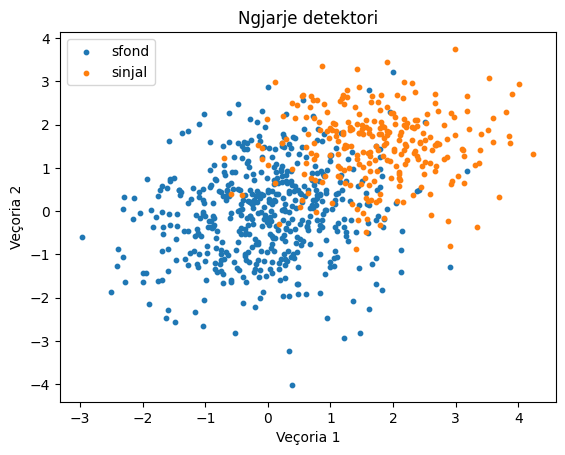

In [2]:
# Qëllimi i këtij blloku: Ndërtimi i problemit sinjal–sfond.
n0, n1 = 500, 260
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
X0 = rng.normal([0.0, 0.0], [1.0, 1.1], size=(n0,2))
# Gjenerojmë të dhëna të kontrolluara që na lejojnë të dimë strukturën që duhet të zbulojë modeli.
X1 = rng.normal([1.8, 1.5], [0.9, 0.8], size=(n1,2))
X = np.vstack([X0, X1]); y = np.r_[np.zeros(n0), np.ones(n1)]

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.scatter(X0[:,0], X0[:,1], s=10, label="sfond")
ax.scatter(X1[:,0], X1[:,1], s=10, label="sinjal")
ax.set_xlabel("Veçoria 1"); ax.set_ylabel("Veçoria 2"); ax.legend()
ax.set_title("Ngjarje detektori")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


# 2. Sigmoid dhe funksioni i humbjes — CORE

### Para se të ekzekutojmë: Nga score linear te probabiliteti

Vizualizojmë sigmoidin për të kuptuar si një score i pakufizuar shndërrohet në vlerë midis 0 dhe 1. Zona rreth $z=0$ është ajo ku modeli është më i pasigurt; larg saj probabiliteti saturon.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


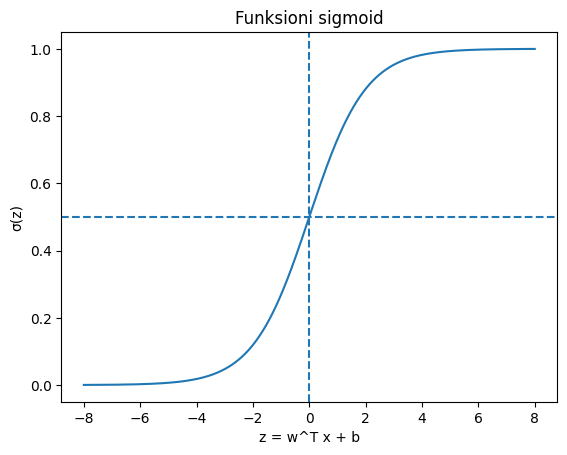

In [3]:
# Qëllimi i këtij blloku: Nga score linear te probabiliteti.
z = np.linspace(-8, 8, 400)
sigmoid = lambda z: 1/(1+np.exp(-z))
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.plot(z, sigmoid(z))
ax.axhline(0.5, linestyle="--"); ax.axvline(0, linestyle="--")
ax.set_xlabel("z = w^T x + b"); ax.set_ylabel("σ(z)")
ax.set_title("Funksioni sigmoid")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


Për një mostër binare, entropia e kryqëzuar (cross-entropy) është
$$
\ell=-\left[y\log p+(1-y)\log(1-p)\right].
$$
Ajo penalizon fort parashikimet shumë të sigurta por të gabuara.

# 3. Zbatim manual me zbritje gradienti — CORE

### Para se të ekzekutojmë: Trajnimi manual i regresionit logjistik

Standardizojmë veçoritë dhe minimizojmë cross-entropy me zbritje gradienti. Historia e humbjes është diagnostikë e optimizimit: para se të besojmë metrikat e klasifikimit, duhet të dimë nëse procedura e trajnimit ka konverguar.

**Parashikim para ekzekutimit.** Cilat statistika duhet të mësohen vetëm nga trajnimi? Parashikoni çfarë rrezikojmë nëse standardizimi ose një transformim tjetër sheh edhe test set-in.


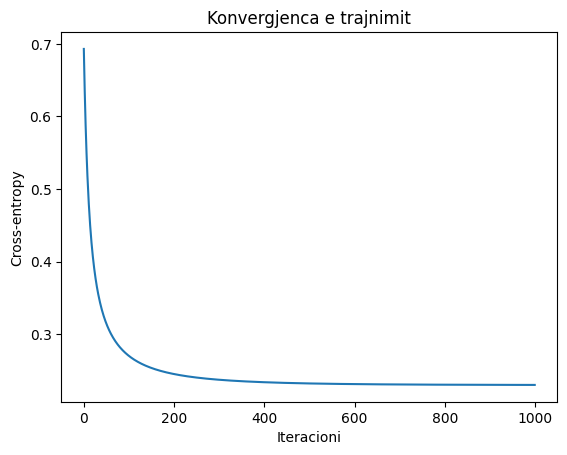

In [4]:
# Qëllimi i këtij blloku: Trajnimi manual i regresionit logjistik.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.preprocessing import StandardScaler
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.model_selection import train_test_split

# Ndajmë të dhënat në mënyrë të riprodhueshme; test-i nuk përdoret për trajnim.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
# Përshtatim standardizimin vetëm mbi të dhënat e trajnimit për të shmangur leakage.
sc = StandardScaler().fit(Xtr)
Xs, Xts = sc.transform(Xtr), sc.transform(Xte)

A = np.c_[np.ones(len(Xs)), Xs]
w = np.zeros(A.shape[1])
loss_hist = []
lr = 0.15
# Përsërisim procedurën për të studiuar konvergjencën ose ndjeshmërinë ndaj parametrave.
for _ in range(1000):
    p = sigmoid(A@w)
    grad = A.T@(p-ytr)/len(ytr)
    w -= lr*grad
    eps=1e-12
    loss_hist.append(-(ytr*np.log(p+eps)+(1-ytr)*np.log(1-p+eps)).mean())

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.plot(loss_hist)
ax.set_xlabel("Iteracioni"); ax.set_ylabel("Cross-entropy")
ax.set_title("Konvergjenca e trajnimit")
plt.show()

**Interpretim.** Ky hap është i vlefshëm vetëm nëse transformimet janë përshtatur pa përdorur informacion nga prova. Një score më i lartë pas rrjedhjes së informacionit nuk është përmirësim shkencor; është shkelje e protokollit të validimit.


### Krahasim me implementimin kanonik në `src/`

### Para se të ekzekutojmë: Kontrolli me implementimin kanonik

Importojmë të njëjtin algoritëm nga `src/` për të verifikuar konsistencën. Ky është kontroll software-ik dhe pedagogjik: implementimi manual na mëson mekanizmin, ndërsa moduli i ripërdorshëm na mëson organizimin e kodit.

**Parashikim para ekzekutimit.** Nëse të dhënat janë të forta të korreluara, prisni që pak eigenvalues të mbajnë pjesën më të madhe të variancës.


In [5]:
# Qëllimi i këtij blloku: Kontrolli me implementimin kanonik.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
import sys
# Kërkojmë automatikisht rrënjën e repository-t, në mënyrë që notebook-u të funksionojë nga dosje të ndryshme.
ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir():
        sys.path.insert(0, str(candidate))
        break
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from src.classification.logistic import LogisticRegressionGD
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
log_src = LogisticRegressionGD(lr=0.15, n_iter=1000).fit(Xs, ytr)
print("Peshat nga src:", np.round(log_src.weights_, 4))

Peshat nga src: [-1.8591  2.4677  2.2062]


**Interpretim.** Komponentët me eigenvalues të mëdha përshkruajnë drejtimet dominante të variacionit. Kjo nuk do të thotë automatikisht se ata janë mekanizma fizikë të pavarur.


# 4. Krahasim me scikit-learn dhe kufiri i vendimit — CORE

### Para se të ekzekutojmë: Kufiri probabilistik i vendimit

Pasi trajnojmë versionin profesional, vizualizojmë vijën ku $P(y=1)=0.5$. Kjo vijë nuk është e vetmja zgjedhje e mundshme; ajo thjesht korrespondon me pragun standard 0.5.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


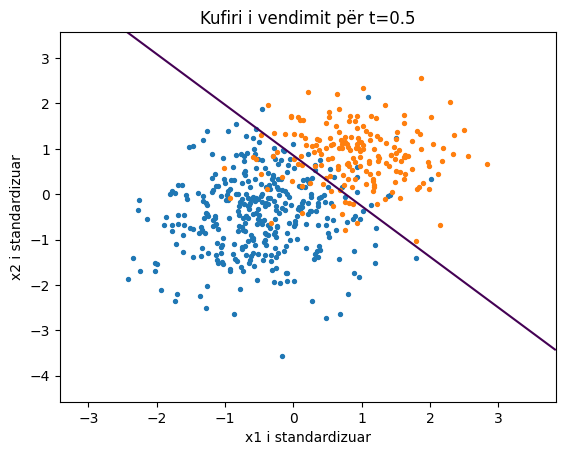

In [6]:
# Qëllimi i këtij blloku: Kufiri probabilistik i vendimit.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.linear_model import LogisticRegression
# Përshtatim parametrat e modelit mbi bashkësinë e trajnimit.
clf = LogisticRegression().fit(Xs, ytr)
# Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
proba = clf.predict_proba(Xts)[:,1]

xx, yy = np.meshgrid(np.linspace(Xs[:,0].min()-1, Xs[:,0].max()+1, 250),
                     np.linspace(Xs[:,1].min()-1, Xs[:,1].max()+1, 250))
# Llogarisim parashikimet mbi të dhëna që nuk përdoren për të ndryshuar parametrat e modelit.
P = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:,1].reshape(xx.shape)

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.contour(xx, yy, P, levels=[0.5])
ax.scatter(Xs[ytr==0,0], Xs[ytr==0,1], s=8)
ax.scatter(Xs[ytr==1,0], Xs[ytr==1,1], s=8)
ax.set_title("Kufiri i vendimit për t=0.5")
ax.set_xlabel("x1 i standardizuar"); ax.set_ylabel("x2 i standardizuar")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


# 5. Confusion matrix dhe pragu — CORE

### Para se të ekzekutojmë: Çfarë lloj gabimi po bëjmë?

Matrica e konfuzionit ndan gabimet në false positives dhe false negatives. Duke ndryshuar pragun, ne zhvendosim qëllimisht balancën ndërmjet tyre. Kjo është pika ku kriteri statistikor lidhet me koston fizike të një vendimi.

**Parashikim para ekzekutimit.** Përpara matricës së konfuzionit, përcaktoni cili lloj gabimi është më i kushtueshëm në problemin fizik. Vetëm pastaj lexoni TP, TN, FP dhe FN.


0.2 precision= 0.707 recall= 0.897 F1= 0.791
0.5 precision= 0.797 recall= 0.756 F1= 0.776
0.8 precision= 0.872 recall= 0.526 F1= 0.656


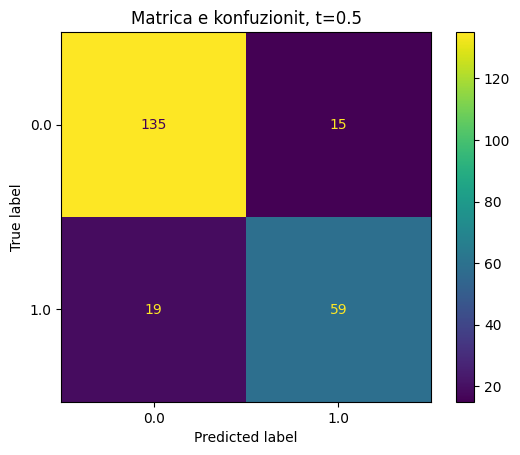

In [7]:
# Qëllimi i këtij blloku: Çfarë lloj gabimi po bëjmë?.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score
for t in [0.2, 0.5, 0.8]:
    pred=(proba>=t).astype(int)
    print(t, "precision=", round(precision_score(yte,pred),3),
          "recall=", round(recall_score(yte,pred),3),
          "F1=", round(f1_score(yte,pred),3))
ConfusionMatrixDisplay.from_predictions(yte, (proba>=0.5).astype(int))
plt.title("Matrica e konfuzionit, t=0.5")
plt.show()

**Interpretim.** Matrica e konfuzionit duhet lexuar në gjuhën e problemit: false positive dhe false negative kanë pasoja të ndryshme. Prandaj një model nuk vlerësohet vetëm nga diagonalia e matricës.


# 6. ROC, AUC dhe precision-recall — CORE

### Para se të ekzekutojmë: Vlerësimi në të gjitha pragjet

ROC dhe precision–recall nuk fiksohen në një prag të vetëm. Ato tregojnë si ndryshon sjellja e klasifikuesit kur lëvizim pragun. AUC mat aftësinë e renditjes, jo domosdoshmërisht cilësinë e kalibrimit probabilistik.

**Parashikim para ekzekutimit.** Mendoni si duhet të lëvizë TPR kur pranojmë më shumë background. Një kurbë e mirë duhet të ngrihet drejt këndit sipër-majtas, por kjo ende nuk zgjedh pragun operacional.


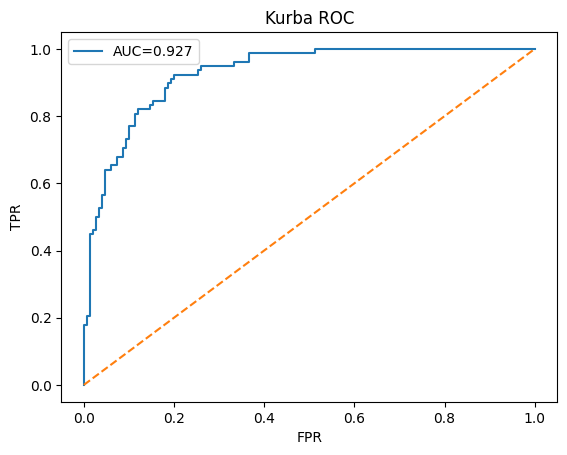

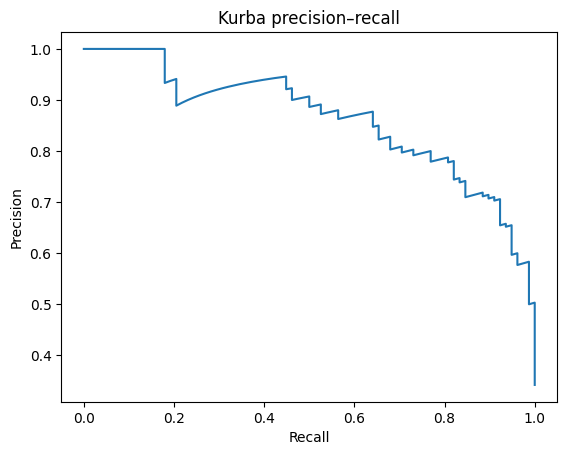

In [8]:
# Qëllimi i këtij blloku: Vlerësimi në të gjitha pragjet.
# Ngarkojmë vetëm mjetet që duhen për këtë hap të analizës.
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
# Llogarisim TPR dhe FPR për të gjitha pragjet e mundshme.
fpr,tpr,_ = roc_curve(yte,proba)
auc=roc_auc_score(yte,proba)
prec,rec,_ = precision_recall_curve(yte,proba)

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.plot(fpr,tpr,label=f"AUC={auc:.3f}")
ax.plot([0,1],[0,1],linestyle="--")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
ax.legend(); ax.set_title("Kurba ROC")
plt.show()

# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.plot(rec,prec)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Kurba precision–recall")
plt.show()

**Interpretim.** ROC mat aftësinë renditëse përgjatë të gjitha pragjeve. AUC e përmbledh këtë në një numër, por nuk përcakton pragun që duhet përdorur në eksperiment.


**Interpretim.** ROC përmbledh kompromisin TPR–FPR në të gjitha pragjet. Precision–recall bëhet veçanërisht i vlefshëm kur klasa pozitive është e rrallë.

Në një analizë reale ky interpretim duhet të shoqërohet me kontroll të njësive, madhësive karakteristike dhe hipotezave që lejojnë kalimin nga një tregues numerik te një përfundim fizik.

---
## Deri këtu: materiali bazë për orën mësimore

Në një seancë rreth 60 minuta, zakonisht ndalemi këtu. Seksionet që vijojnë janë për thellim,
ushtrime të pavarura dhe eksperimentim.

# 7. Si ndryshon pragu optimal? — EXTENDED

### Para se të ekzekutojmë: Zgjedhja e pragut si problem shkencor

Vizualizojmë precision, recall dhe F1 si funksion të pragut. Kjo e bën të qartë se “pragu optimal” ekziston vetëm pasi kemi përcaktuar se çfarë vlerësojmë dhe çfarë kostoje kanë gabimet.

**Parashikim para ekzekutimit.** Vendosni çfarë forme duhet të ketë figura nëse argumenti teorik është i saktë. Grafiku përdoret për të testuar një pritshmëri, jo vetëm për ta ilustruar.


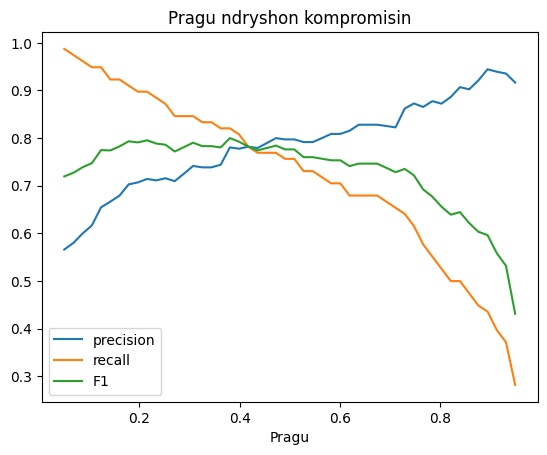

In [9]:
# Qëllimi i këtij blloku: Zgjedhja e pragut si problem shkencor.
thresholds=np.linspace(0.05,0.95,50)
Ps,Rs,F1s=[],[],[]
for t in thresholds:
    pred=(proba>=t).astype(int)
    Ps.append(precision_score(yte,pred,zero_division=0))
    Rs.append(recall_score(yte,pred,zero_division=0))
    F1s.append(f1_score(yte,pred,zero_division=0))
# Ndërtojmë një figurë diagnostike; grafiku është pjesë e analizës, jo dekorim.
fig, ax = plt.subplots()
ax.plot(thresholds,Ps,label="precision")
ax.plot(thresholds,Rs,label="recall")
ax.plot(thresholds,F1s,label="F1")
ax.set_xlabel("Pragu"); ax.legend(); ax.set_title("Pragu ndryshon kompromisin")
plt.show()

**Interpretim.** Figura duhet lexuar si test i një hipoteze të vogël: a përputhet forma e vëzhguar me atë që parashikuam nga matematika?


# 8. Aplikim jo-fizik: diagnozë mjekësore — EXTENDED

Në screening mjekësor kostoja e një false negative mund të jetë shumë më e lartë se ajo e një false positive; prandaj pragu nuk duhet zgjedhur vetëm për të maksimizuar accuracy.

## Punishtja — ndrysho, mat dhe shpjego

Në këtë pjesë nuk kërkohet ekzekutim pasiv. Për çdo eksperiment:

1. shkruani paraprakisht çfarë prisni të ndodhë;
2. ndryshoni **vetëm një** element në të njëjtën kohë;
3. ruani metrikën ose figurën që ndryshon;
4. shpjegoni mekanizmin matematik ose statistikor;
5. dalloni qartë atë që tregon eksperimenti nga ajo që **nuk** mund të përfundohet prej tij.

### Pyetje për diskutim

1. Pse cross-entropy është më e përshtatshme se MSE për probabilitete binare?
2. Çfarë do të thotë fizikisht një false negative?
3. Pse ROC nuk zgjedh vetë pragun operacional?
4. Kur precision–recall është më informative se ROC?


# Ushtrime — PLAYGROUND

        ## A. Ushtrime të shkurtra
        1. Llogaritni specificity për pragjet 0.2, 0.5 dhe 0.8.
2. Gjeni pragun që jep recall ≥ 0.95 me precision maksimal.
3. Shpjegoni interpretimin probabilistik të AUC.
4. Krahasoni ROC me precision-recall për një klasë pozitive 5%.

        ## B. Ushtrim i plotë
        Krijoni një problem të pabalancuar 95:5, trajnojeni regresionin logjistik dhe diskutoni pse accuracy mund të jetë mashtruese.

        ## C. Playground
        Ndryshoni distancën ndërmjet klasave, pabalancimin dhe pragun.

In [10]:
# TODO / PLAYGROUND
# Ndryshoni parametrat, shtoni grafikë ose krahasoni modele të tjera.

## Përmbledhje konceptuale e kapitullit

Notebook-u **Klasifikimi dhe regresioni logjistik** duhet të lihet me një ide të qartë: algoritmi është vetëm një hallkë e arsyetimit. Para tij kemi zgjedhjen e përfaqësimit dhe hipotezat mbi të dhënat; pas tij kemi validimin, diagnostikën dhe interpretimin. Nëse një student mund të ekzekutojë të gjitha qelizat por nuk mund të shpjegojë pse secila prej tyre është e nevojshme, atëherë puna llogaritëse nuk është përfunduar ende.

Për studim të mëtejshëm, rikthehuni te shënimet e leksionit për derivimet e plota dhe përdoreni këtë notebook si laborator ku këto ide testohen numerikisht.

### Zgjidhje orientuese për instruktorin
- Specificity është $TN/(TN+FP)$.
- Nëse kërkohet recall i lartë, pragu zakonisht ulet; kjo rrit false positives.
- AUC mund të interpretohet si probabiliteti që një mostër pozitive të renditet mbi një negative.
- Në klasa shumë të pabalancuara, precision–recall është shpesh më informative se accuracy.

## Kontrolli përfundimtar

- [ ] Interpretoj sigmoidin.
- [ ] Lidh probabilitetin me pragun e vendimit.
- [ ] Llogaris precision, recall, specificity dhe F1.
- [ ] Interpretoj ROC dhe AUC.
- [ ] Zgjedh pragun sipas kostos shkencore të gabimeve.
